# 04 — `scipy.stats` (Pusat Distribusi Probabilitas & Uji Statistik)
**Mata Kuliah:** Probabilitas dan Statistika | **Nama / NIM:** ________

`scipy.stats` adalah library paling lengkap: >100 distribusi dengan antarmuka seragam, ditambah entropi, uji hipotesis, *fitting*, dan *bootstrap*.

## 1. Eksplorasi Library
**Metode seragam pada setiap distribusi** (`rv = stats.binom(n=10,p=.2)`):

| Metode | Arti | Metode | Arti |
|---|---|---|---|
| `pmf(k)` / `pdf(x)` | P(X=k) / kepadatan | `ppf(q)` | kuantil (invers CDF) |
| `cdf(x)` | P(X≤x) | `isf(q)` | invers SF |
| `sf(x)` | P(X>x)=1−cdf | `rvs(size)` | bangkitkan sampel |
| `mean() var() std()` | momen | `stats(moments='mvsk')` | mean, var, skew, kurtosis |
| `expect(func)` | E[g(X)] | `interval(c)` | selang pusat c |
| `entropy()` | entropi | `dist.fit(data)` | estimasi parameter (MLE) |

**Parameterisasi yang wajib diingat:** `norm(loc=μ, scale=σ)` · `expon(scale=1/λ)` · `uniform(loc=a, scale=b−a)` · `geom(p)` mulai k=1 · `nbinom(r,p)` menghitung **jumlah gagal** · `hypergeom(M,n,N)` · `poisson(mu)` · `weibull_min(c, scale=λ)` · `lognorm(s=σ, scale=e^μ)`.

In [1]:
import numpy as np, math, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
print("scipy.stats versi:", __import__('scipy').__version__)
print("Jumlah distribusi kontinu:", len(stats._continuous_distns._distn_names), "| diskrit:", len(stats._discrete_distns._distn_names))
X=stats.binom(10,0.2)
print("pmf(3)=",X.pmf(3).round(4)," cdf(3)=",X.cdf(3).round(4)," sf(3)=",X.sf(3).round(4)," ppf(.95)=",X.ppf(.95))
print("stats(mvsk)=",X.stats(moments='mvsk'))
print("E[X^2]=",X.expect(lambda k:k**2)," interval(95%)=",X.interval(.95))

scipy.stats versi: 1.18.1
Jumlah distribusi kontinu: 109 | diskrit: 21
pmf(3)= 0.2013  cdf(3)= 0.8791  sf(3)= 0.1209  ppf(.95)= 4.0
stats(mvsk)= (np.float64(2.0), np.float64(1.5999999999999999), np.float64(0.47434164902525683), np.float64(0.025000000000000022))
E[X^2]= 5.599999999999997  interval(95%)= (np.float64(0.0), np.float64(5.0))


## 2. Implementasi pada Permasalahan Probabilitas
### Soal 2.1 — Distribusi diskrit kustom (`rv_discrete`): dadu tidak adil
Dadu berpeluang (1..6) = (0,1; 0,1; 0,1; 0,1; 0,2; 0,4). Hitung E, Var, P(X≥5) dan P(jumlah 2 lemparan = 10).
**Manual:** E=0,1(1+2+3+4)+0,2·5+0,4·6=1+1+2,4=**4,4**.

In [2]:
vals=np.arange(1,7); pr=[.1,.1,.1,.1,.2,.4]
D=stats.rv_discrete(name='dadu_curang',values=(vals,pr))
print("E =",D.mean()," Var =",round(D.var(),3)," P(X>=5)=",D.sf(4))
# jumlah dua lemparan (konvolusi)
conv=np.convolve(pr,pr)            # indeks 0 -> jumlah 2
print("P(jumlah=10) =",round(conv[10-2],4),"")
manual=pr[3]*pr[5]*2+pr[4]**2
print("manual       =",round(manual,4))
s=D.rvs(size=200_000,random_state=1)
print("sim mean =",s.mean().round(3))

E = 4.4  Var = 3.04  P(X>=5)= 0.6
P(jumlah=10) = 0.12 
manual       = 0.12
sim mean = 4.396


**Interpretasi:** `rv_discrete` menjadikan tabel peluang apa pun sebagai distribusi lengkap (mean, var, rvs). Konvolusi (`np.convolve`) menghitung distribusi jumlah dua variabel independen, cocok dengan hitungan manual 2·(0,1·0,4)+0,2²=0,12.

### Soal 2.2 — Hukum probabilitas total & Bayes: sumber error pada 3 server
Server A,B,C melayani 50%, 30%, 20% trafik dengan tingkat error 1%, 2%, 5%. Jika satu request error, server mana paling mungkin sumbernya?
**Manual:** P(E)=0,005+0,006+0,010=0,021; P(A|E)=0,238; P(B|E)=0,286; P(C|E)=0,476.

In [3]:
prior=np.array([.5,.3,.2]); like=np.array([.01,.02,.05])
joint=prior*like; pE=joint.sum(); post=joint/pE
print(pd.DataFrame({"prior":prior,"P(E|server)":like,"joint":joint,"posterior":post.round(4)},index=list("ABC")))
print("P(error) =",round(pE,4))
# verifikasi dengan simulasi
rng=np.random.default_rng(0); N=3_000_000
srv=rng.choice(3,N,p=prior); err=rng.random(N)<like[srv]
print("sim posterior:",np.bincount(srv[err],minlength=3)/err.sum())

   prior  P(E|server)  joint  posterior
A    0.5         0.01  0.005     0.2381
B    0.3         0.02  0.006     0.2857
C    0.2         0.05  0.010     0.4762
P(error) = 0.021
sim posterior: [0.23798605 0.28839798 0.47361596]


**Interpretasi:** Server C hanya menangani 20% trafik, tetapi karena tingkat error tertinggi, ia menjadi sumber paling mungkin (47,6%). Prior (beban) dan likelihood (kualitas) harus digabungkan — pola inti dalam *debugging* probabilistik.

### Soal 2.3 — Uji independensi: apakah jenis OS memengaruhi jenis serangan? (`chi2_contingency`)
Tabel kontingensi log insiden: baris=OS (Windows, Linux), kolom=serangan (Malware, Phishing, DDoS).

In [4]:
obs=np.array([[120,80,40],[30,70,60]])
chi2,p,dof,exp=stats.chi2_contingency(obs)
print("tabel harapan jika independen:\n",exp.round(1))
print(f"chi2={chi2:.2f}, dof={dof}, p-value={p:.2e}")
print("P(Malware|Windows) =",round(120/240,3)," P(Malware|Linux) =",round(30/160,3))
print("Cramér's V =", round(math.sqrt(chi2/(obs.sum()*(min(obs.shape)-1))),3))

tabel harapan jika independen:
 [[90. 90. 60.]
 [60. 60. 40.]]
chi2=44.44, dof=2, p-value=2.23e-10
P(Malware|Windows) = 0.5  P(Malware|Linux) = 0.188
Cramér's V = 0.333


**Interpretasi:** p-value jauh di bawah 0,05 → tolak hipotesis independensi: jenis serangan **bergantung** pada OS (malware 50% pada Windows vs 18,8% pada Linux). Cramér's V mengukur kekuatan hubungan (0–1).

### Soal 2.4 — Entropi & informasi (`stats.entropy`)
Bandingkan entropi password acak 8 karakter (36 simbol) dengan password manusia (distribusi huruf tidak seragam), dan hitung KL-divergence.

In [5]:
uniform=np.ones(36)/36
skew=np.array([.12,.09,.08,.07,.06,.06]+[0.52/30]*30)   # distribusi miring
H_u=stats.entropy(uniform,base=2); H_s=stats.entropy(skew,base=2)
print("Entropi per karakter uniform:",round(H_u,3),"bit  -> 8 karakter:",round(8*H_u,1),"bit")
print("Entropi per karakter miring :",round(H_s,3),"bit  -> 8 karakter:",round(8*H_s,1),"bit")
print("KL(skew||uniform)           :",round(stats.entropy(skew,uniform,base=2),3),"bit")
print("Penyerang pintar cukup ~2^",round(8*H_s,1),"tebakan, bukan 2^",round(8*H_u,1))

Entropi per karakter uniform: 5.17 bit  -> 8 karakter: 41.4 bit
Entropi per karakter miring : 4.769 bit  -> 8 karakter: 38.2 bit
KL(skew||uniform)           : 0.401 bit
Penyerang pintar cukup ~2^ 38.2 tebakan, bukan 2^ 41.4


**Interpretasi:** Distribusi seragam memaksimalkan entropi (log₂36≈5,17 bit/karakter). Pola pilihan manusia menurunkan entropi sehingga ruang pencarian efektif jauh lebih kecil — alasan password acak lebih kuat dari "password manusia". KL-divergence mengukur seberapa jauh pola manusia dari acak sempurna.

## 3. Implementasi pada Distribusi Probabilitas
### Soal 3.1 — Binomial: transmisi paket
n=50 paket, p(gagal)=0,04. Hitung P(X=0), P(X≥5), kuantil 99%, dan E/Var. Visualisasikan PMF dan CDF.

P(X=0)= 0.1299  P(X>=5)= 0.049  P99= 6.0
E= 2.0  Var= 1.92  sd= 1.386


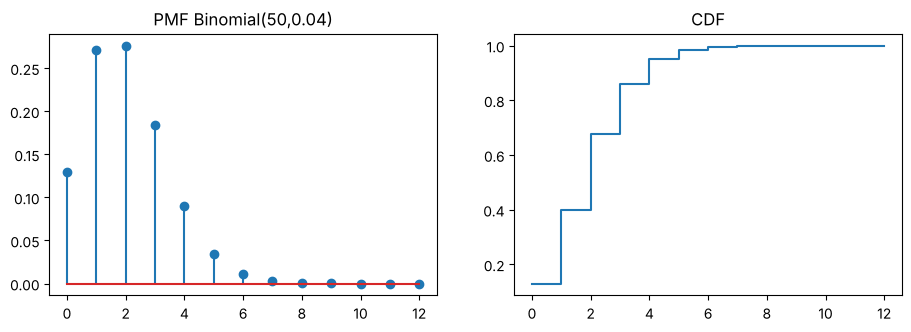

In [6]:
X=stats.binom(50,.04)
print("P(X=0)=",X.pmf(0).round(4)," P(X>=5)=",X.sf(4).round(4)," P99=",X.ppf(.99))
print("E=",X.mean()," Var=",round(X.var(),3)," sd=",round(X.std(),3))
k=np.arange(0,13)
fig,ax=plt.subplots(1,2,figsize=(11,3.4))
ax[0].stem(k,X.pmf(k)); ax[0].set_title("PMF Binomial(50,0.04)")
ax[1].step(k,X.cdf(k),where='post'); ax[1].set_title("CDF"); plt.show()

**Interpretasi:** Peluang semua paket sukses hanya ±13% (0,96⁵⁰), rata-rata 2 paket gagal; peluang ≥5 gagal kecil (±4,9%). Kuantil 99% = 6 → protokol perlu menyiapkan buffer retransmisi untuk ±6 paket agar 99% kasus tertangani.

### Soal 3.2 — Poisson: kapasitas server
Request rata-rata 120/menit. (a) P(>140 dalam 1 menit)? (b) Kapasitas minimum agar P(overload)≤1%? (c) Bandingkan dengan pendekatan Normal.

P(X>140)  = 0.0331
Kapasitas (P99) = 146.0  -> P(X>cap) = 0.0093
Pendekatan Normal P(X>140.5): 0.0306


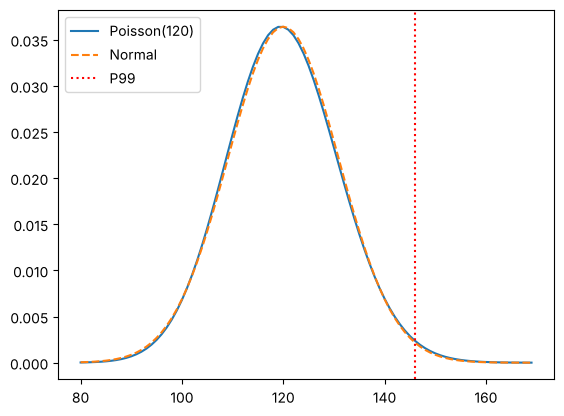

In [7]:
X=stats.poisson(120)
print("P(X>140)  =",X.sf(140).round(4))
cap=X.ppf(.99); print("Kapasitas (P99) =",cap," -> P(X>cap) =",X.sf(cap).round(4))
print("Pendekatan Normal P(X>140.5):",stats.norm(120,math.sqrt(120)).sf(140.5).round(4))
k=np.arange(80,170); plt.plot(k,X.pmf(k),label="Poisson(120)"); plt.plot(k,stats.norm(120,math.sqrt(120)).pdf(k),'--',label="Normal"); plt.axvline(cap,c='r',ls=':',label="P99"); plt.legend(); plt.show()

**Interpretasi:** `ppf` menjawab pertanyaan perencanaan kapasitas langsung: siapkan server untuk ±146 request/menit agar overload ≤1%. Untuk λ besar, Poisson ≈ Normal(λ, √λ) sehingga kedua kurva hampir berimpit.

### Soal 3.3 — Geometrik vs Binomial Negatif: jebakan konvensi SciPy
Peluang sukses koneksi p=0,3. (a) P(sukses pertama di percobaan ke-4)? (b) P(sukses ke-3 terjadi pada percobaan ke-10)? 
**Manual (b):** C(9,2)(0,3)³(0,7)⁷≈0,0800. `nbinom` menghitung **jumlah gagal** sebelum sukses ke-r, jadi gagal = 10−3 = 7.

In [8]:
p=.3
print("(a) geom.pmf(4)       =",stats.geom(p).pmf(4).round(4),"  manual:",round(.7**3*.3,4))
r=3
print("(b) nbinom.pmf(7)     =",stats.nbinom(r,p).pmf(7).round(4),"  manual:",round(math.comb(9,2)*.3**3*.7**7,4))
print("Salah kaprah nbinom.pmf(10) =",stats.nbinom(r,p).pmf(10).round(4),"<- BUKAN jawaban")
print("E[total percobaan] = r/p =",r/p," | E[gagal] =",stats.nbinom(r,p).mean())

(a) geom.pmf(4)       = 0.1029   manual: 0.1029
(b) nbinom.pmf(7)     = 0.08   manual: 0.08
Salah kaprah nbinom.pmf(10) = 0.0503 <- BUKAN jawaban
E[total percobaan] = r/p = 10.0  | E[gagal] = 6.999999999999999


**Interpretasi:** `nbinom` adalah distribusi jumlah **kegagalan**, sehingga total percobaan = gagal + r. Rata-rata total percobaan = r/p = 10, sedangkan rata-rata gagal = 7. Kesalahan konvensi ini sering terjadi, termasuk pada kode yang dihasilkan AI.

### Soal 3.4 — Hipergeometrik: audit bug (tanpa pengembalian)
50 modul memuat 8 bug. Tester menguji 10 modul. (a) P(0 bug ditemukan)? (b) P(≥3 bug)? (c) E?

P(X=0)= 0.1432  P(X>=3)= 0.1878  E= 1.6  Var= 1.0971
Binomial pendekatan: P(X=0)= 0.1749


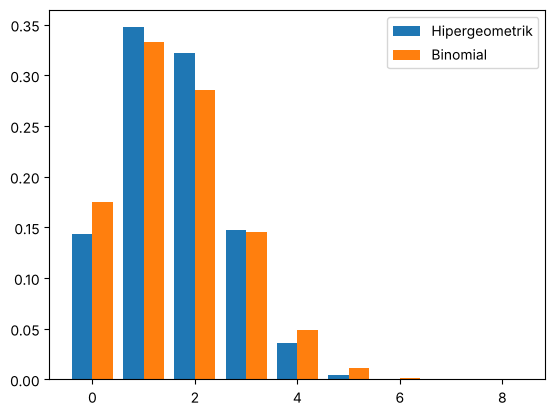

In [9]:
H=stats.hypergeom(M=50,n=8,N=10)
print("P(X=0)=",H.pmf(0).round(4)," P(X>=3)=",H.sf(2).round(4)," E=",H.mean()," Var=",round(H.var(),4))
print("Binomial pendekatan: P(X=0)=",stats.binom(10,8/50).pmf(0).round(4))
k=np.arange(0,9); plt.bar(k-.2,H.pmf(k),.4,label="Hipergeometrik"); plt.bar(k+.2,stats.binom(10,.16).pmf(k),.4,label="Binomial"); plt.legend(); plt.show()

**Interpretasi:** Peluang tidak menemukan satu bug pun adalah ±14% walau 16% modul berbug. Hipergeometrik memberi variansi lebih kecil daripada Binomial karena tidak ada pengembalian.

### Soal 3.5 — Normal: latensi & CI (`norm`, `t`)
Latensi ~ N(200, 30²). (a) P(X>250); (b) lebar interval 95% tengah; (c) selang kepercayaan rata-rata dari 10 sampel memakai distribusi t.

P(X>250)= 0.0478  interval95= (np.float64(141.2), np.float64(258.8))
mean sampel= 207.0  CI95 (t)= (np.float64(184.9), np.float64(229.1))
t kritis (df=9) = 2.262  vs z kritis = 1.96
fit MLE: mu=200.7 sd=30.1


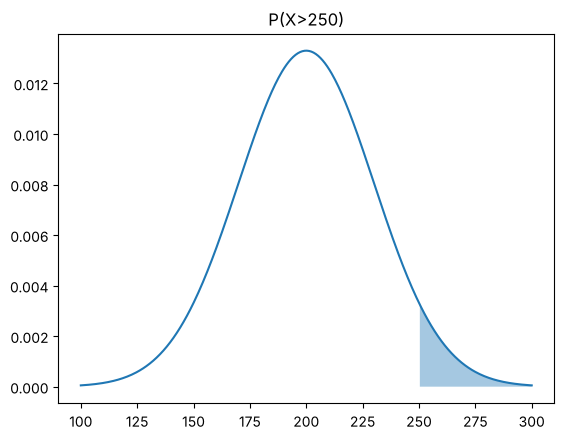

In [10]:
X=stats.norm(200,30)
print("P(X>250)=",X.sf(250).round(4)," interval95=",tuple(np.round(X.interval(.95),1)))
sample=X.rvs(10,random_state=5)
m,se=sample.mean(),stats.sem(sample)
print("mean sampel=",m.round(1)," CI95 (t)=",tuple(np.round(stats.t.interval(.95,df=9,loc=m,scale=se),1)))
print("t kritis (df=9) =",stats.t.ppf(.975,9).round(3)," vs z kritis =",stats.norm.ppf(.975).round(3))
mu,sd=stats.norm.fit(X.rvs(5000,random_state=1)); print("fit MLE: mu=%.1f sd=%.1f"%(mu,sd))
x=np.linspace(100,300,400); plt.plot(x,X.pdf(x)); plt.fill_between(x,X.pdf(x),where=x>250,alpha=.4); plt.title("P(X>250)"); plt.show()

**Interpretasi:** ±4,8% permintaan >250 ms. Dengan sampel kecil, nilai kritis t (2,262) lebih besar daripada z (1,96) sehingga CI lebih lebar — kompensasi ketidakpastian estimasi σ.

### Soal 3.6 — Eksponensial & Gamma: antrean dan waktu tunggu
Request tiba dengan λ=4/dtk. (a) P(jeda>0,5 dtk); (b) peluang menunggu ≤1 dtk sampai 3 request tiba (Gamma/Erlang k=3).
**Manual:** (a) e⁻²=0,1353; (b) P(Poisson(4)≥3)=1−e⁻⁴(1+4+8)=0,7619.

(a) P(T>0.5)= 0.1353  E[T]= 0.25  memoryless: P(T>1.5|T>1)= 0.1353
(b) P(G<=1)= 0.7619   via Poisson: 0.7619
E[G]= 0.75  Var= 0.1875


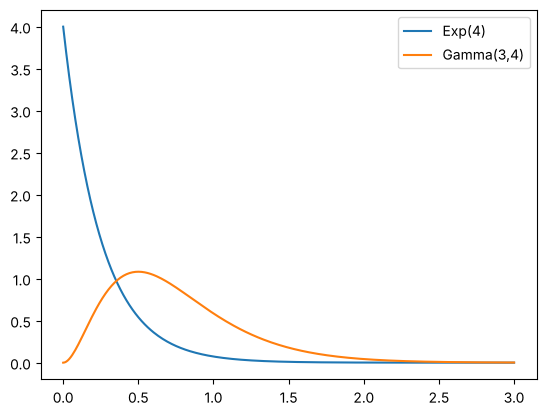

In [11]:
lam=4
E=stats.expon(scale=1/lam); G=stats.gamma(a=3,scale=1/lam)
print("(a) P(T>0.5)=",E.sf(.5).round(4)," E[T]=",E.mean()," memoryless: P(T>1.5|T>1)=",(E.sf(1.5)/E.sf(1)).round(4))
print("(b) P(G<=1)=",G.cdf(1).round(4),"  via Poisson:",stats.poisson(4).sf(2).round(4))
print("E[G]=",G.mean()," Var=",G.var())
x=np.linspace(0,3,300); plt.plot(x,E.pdf(x),label="Exp(4)"); plt.plot(x,G.pdf(x),label="Gamma(3,4)"); plt.legend(); plt.show()

**Interpretasi:** Sifat *memoryless*: P(T>1,5|T>1)=P(T>0,5)=0,1353. Gamma(3) = jumlah 3 Eksponensial, dan CDF-nya identik dengan P(Poisson(λt) ≥ 3) — bukti hubungan Poisson–Eksponensial–Gamma.

### Soal 3.7 — Weibull: keandalan hardware dan fungsi hazard
Umur disk ~ Weibull(k=1,5; λ=1000 jam). Hitung R(500), rata-rata umur, median, dan laju kegagalan h(t).

R(500)= 0.7022  mean= 902.7  median= 783.2


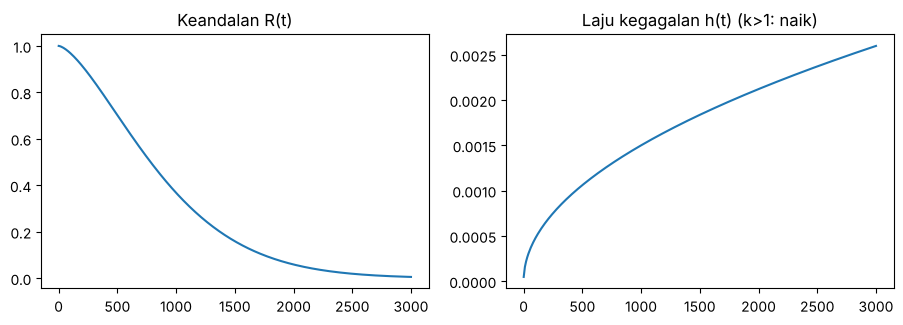

k= 0.7  -> tren hazard: turun (infant mortality)
k= 1  -> tren hazard: konstan
k= 1.5  -> tren hazard: naik (aus)


In [12]:
W=stats.weibull_min(c=1.5,scale=1000)
print("R(500)=",W.sf(500).round(4)," mean=",W.mean().round(1)," median=",W.median().round(1))
t=np.linspace(1,3000,300); h=W.pdf(t)/W.sf(t)
fig,ax=plt.subplots(1,2,figsize=(11,3.3))
ax[0].plot(t,W.sf(t)); ax[0].set_title("Keandalan R(t)")
ax[1].plot(t,h); ax[1].set_title("Laju kegagalan h(t) (k>1: naik)")
plt.show()
for k in (0.7,1,1.5): print("k=",k," -> tren hazard:", "turun (infant mortality)" if k<1 else "konstan" if k==1 else "naik (aus)")

**Interpretasi:** Karena k>1 laju kegagalan naik terhadap waktu (komponen aus). R(500)≈0,70. k<1 memodelkan *infant mortality*, k=1 menjadi Eksponensial (laju konstan) — Weibull menyatukan ketiga fase kurva *bathtub*.

### Soal 3.8 — Distribusi *heavy-tail*: ukuran file (Log-normal) & trafik (Pareto)
Bandingkan ukuran file ~ Lognormal(μ=8, σ=1,5) dan Pareto(b=1,5): rata-rata vs median, dan peluang file sangat besar.

Lognormal: mean=9182 median=2981  P(X>100000)=0.0096
Pareto   : mean=3000 median=1587  P(X>100000)=0.00100  var=inf


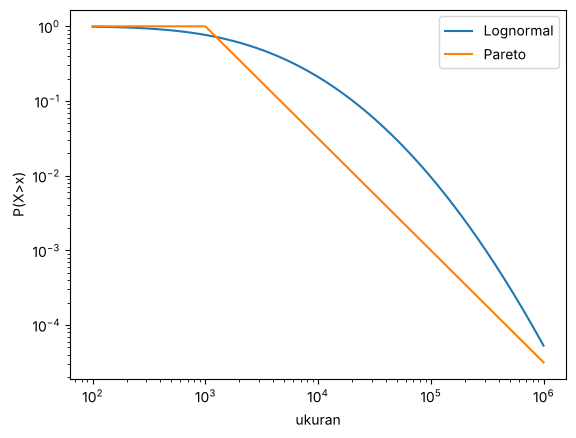

In [13]:
L=stats.lognorm(s=1.5,scale=math.exp(8)); P=stats.pareto(b=1.5,scale=1000)
print("Lognormal: mean=%.0f median=%.0f  P(X>100000)=%.4f"%(L.mean(),L.median(),L.sf(1e5)))
print("Pareto   : mean=%.0f median=%.0f  P(X>100000)=%.5f  var=%s"%(P.mean(),P.median(),P.sf(1e5),P.var()))
x=np.logspace(2,6,300); plt.loglog(x,L.sf(x),label="Lognormal"); plt.loglog(x,P.sf(x),label="Pareto"); plt.xlabel("ukuran"); plt.ylabel("P(X>x)"); plt.legend(); plt.show()

**Interpretasi:** Mean jauh di atas median → distribusi sangat miring: sedikit file raksasa mendominasi total. Pada Pareto α=1,5 variansnya **tak hingga**, dan di grafik log-log ekornya turun lurus (hukum pangkat) lebih lambat daripada Lognormal. Konsekuensinya: rata-rata sampel tidak stabil, desain cache/bandwidth harus memperhitungkan ekor.

### Soal 3.9 — Fitting distribusi & uji kecocokan (`fit`, `kstest`, `chisquare`)
Data waktu antar-kedatangan (disintesis dari Eksponensial λ=2). (a) estimasi parameter, (b) uji K–S terhadap Eksponensial dan Normal, (c) uji χ² untuk data hitungan Poisson.

fit expon: lambda_hat= 2.046 (sebenarnya 2)
KS vs Expon : KstestResult(statistic=np.float64(0.02833384794297389), pvalue=np.float64(0.5324436556411501), statistic_location=np.float64(0.4003415919095024), statistic_sign=np.int8(1))
KS vs Normal: KstestResult(statistic=np.float64(0.1606322232204042), pvalue=np.float64(1.6803382866791159e-18), statistic_location=np.float64(0.0012427562984826698), statistic_sign=np.int8(-1))
chi2 Poisson: Power_divergenceResult(statistic=np.float64(6.624965982670801), pvalue=np.float64(0.46894337112096185))


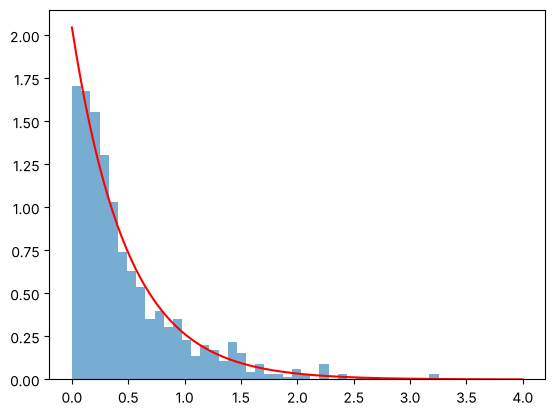

In [14]:
data=stats.expon(scale=.5).rvs(800,random_state=2)
loc,scale=stats.expon.fit(data,floc=0); print("fit expon: lambda_hat=",round(1/scale,3),"(sebenarnya 2)")
print("KS vs Expon :",stats.kstest(data,stats.expon(scale=scale).cdf))
mu,sd=stats.norm.fit(data); print("KS vs Normal:",stats.kstest(data,stats.norm(mu,sd).cdf))
# chi-square untuk Poisson
cnt=stats.poisson(3).rvs(1000,random_state=3); obs=np.bincount(np.minimum(cnt,8),minlength=9)
pr=stats.poisson(cnt.mean()).pmf(np.arange(8)); pr=np.append(pr,1-pr.sum())
res=stats.chisquare(obs,pr*1000,ddof=1); print("chi2 Poisson:",res)
plt.hist(data,bins=40,density=True,alpha=.6); x=np.linspace(0,4,200); plt.plot(x,stats.expon(scale=scale).pdf(x),'r'); plt.show()

**Interpretasi:** λ̂≈2 mendekati nilai sebenarnya. Uji K–S tidak menolak Eksponensial (p besar) tetapi menolak Normal (p≈0): kita boleh mengabaikan model Normal untuk data ini. Uji χ² (p>0,05) mendukung bahwa data hitungan konsisten dengan Poisson.

### Soal 3.10 — Multinomial: sebaran trafik ke tiga server
10 request dibagi ke server A,B,C dengan peluang (0,5; 0,3; 0,2). P(tepat 5-3-2)? E dan kovarians?

In [15]:
M=stats.multinomial(10,[.5,.3,.2])
print("P(5,3,2) =",M.pmf([5,3,2]).round(4)," P(4,3,3)=",M.pmf([4,3,3]).round(4))
print("E =",M.mean()," var =",M.cov().diagonal().round(2))
print("cov(A,B)=",M.cov()[0,1].round(2),"(negatif: A naik, B cenderung turun)")

P(5,3,2) = 0.085  P(4,3,3)= 0.0567
E = [5. 3. 2.]  var = [2.5 2.1 1.6]
cov(A,B)= -1.5 (negatif: A naik, B cenderung turun)


**Interpretasi:** Komponen multinomial saling berkorelasi negatif karena totalnya tetap (10). Distribusi marginal tiap server adalah Binomial(10, p_i).

## 4. Pengembangan Contoh Permasalahan
### Soal 4.1 — A/B Testing Bayesian (Beta–Binomial)
Tombol A: 30 klik dari 200 tayangan. Tombol B: 45 dari 200. Prior Beta(1,1). Hitung posterior, P(B>A) dan CI kredibel untuk selisih.
**Manual:** posterior A=Beta(31,171), B=Beta(46,156); mean 0,153 vs 0,228.

mean posterior A=0.153 B=0.228


P(B>A)= 0.9726  selisih mean= 0.0743  CI95= [-0.002  0.15 ]
uji frekuentis (chi2): 0.0547


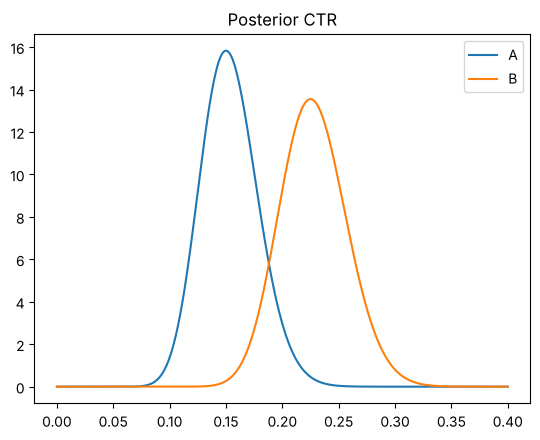

In [16]:
A=stats.beta(1+30,1+170); B=stats.beta(1+45,1+155)
print("mean posterior A=%.3f B=%.3f"%(A.mean(),B.mean()))
a=A.rvs(200_000,random_state=1); b=B.rvs(200_000,random_state=2)
print("P(B>A)=",(b>a).mean().round(4)," selisih mean=",(b-a).mean().round(4)," CI95=",np.percentile(b-a,[2.5,97.5]).round(3))
print("uji frekuentis (chi2):",stats.chi2_contingency([[30,170],[45,155]],correction=False)[1].round(4))
x=np.linspace(0,.4,400); plt.plot(x,A.pdf(x),label="A"); plt.plot(x,B.pdf(x),label="B"); plt.legend(); plt.title("Posterior CTR"); plt.show()

**Interpretasi:** P(B>A)≈0,97 dan selisih rata-rata ≈0,074, tetapi CI95 kredibel [−0,002; 0,15] nyaris menyentuh 0, selaras dengan uji χ² frekuentis yang borderline (p≈0,055, tidak signifikan pada α=0,05). Pendekatan Bayes langsung menjawab "berapa peluang B lebih baik?" (±97%), sedangkan p-value hanya menyatakan peluang data ekstrem bila H₀ benar. Keputusan praktisnya: B kemungkinan besar lebih baik, namun pertimbangkan menambah data.

### Soal 4.2 — Cache & distribusi Zipf: popularitas konten
Katalog 1000 item, popularitas Zipf (a=1). Cache menyimpan 50 item terpopuler. Berapa *hit ratio*?

cache  10 item -> hit ratio 0.391
cache  50 item -> hit ratio 0.601
cache 100 item -> hit ratio 0.693
cache 200 item -> hit ratio 0.785
P(item peringkat 1)= 0.1336  peringkat 100= 0.00134


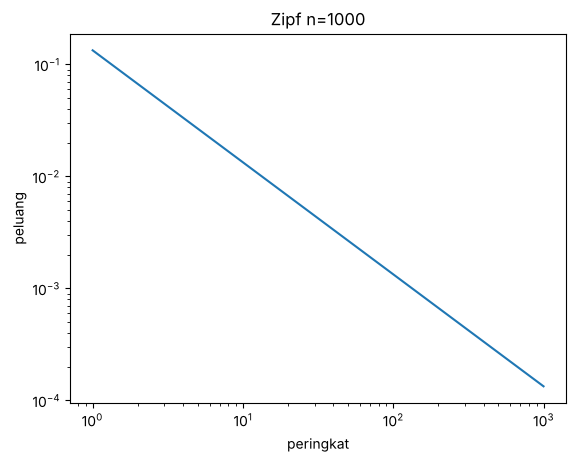

In [17]:
Z=stats.zipfian(a=1.0,n=1000)
for c in (10,50,100,200): print(f"cache {c:>3} item -> hit ratio {Z.cdf(c):.3f}")
print("P(item peringkat 1)=",Z.pmf(1).round(4)," peringkat 100=",Z.pmf(100).round(5))
k=np.arange(1,1001); plt.loglog(k,Z.pmf(k)); plt.xlabel("peringkat"); plt.ylabel("peluang"); plt.title("Zipf n=1000"); plt.show()

**Interpretasi:** Dengan cache hanya 5% katalog (50 item), ±60% permintaan terlayani — berkat sifat Zipf (sedikit item sangat populer). Hasilnya mengikuti H₅₀/H₁₀₀₀ dan menjelaskan efektivitas CDN/cache.

### Soal 4.3 — Jumlah variabel Normal independen: SLA end-to-end
Request melewati 3 layanan dengan latensi N(50,8²), N(80,12²), N(30,5²). Hitung P(total ≤ 190 ms), batas SLA P99, dan kontribusi variansi tiap layanan.
**Manual:** total ~ N(160, 8²+12²+5²=233) → σ=15,26; z=(190−160)/15,26=1,966.

In [18]:
mu=np.array([50,80,30]); sd=np.array([8,12,5])
T=stats.norm(mu.sum(),math.sqrt((sd**2).sum()))
print("Total ~ N(%.0f, %.2f)"%(T.mean(),T.std()))
print("P(total<=190)=",T.cdf(190).round(4)," P99=",T.ppf(.99).round(1)," ms")
print("kontribusi variansi:",((sd**2)/(sd**2).sum()).round(3))
rng=np.random.default_rng(1); S=rng.normal(mu,sd,(1_000_000,3)).sum(axis=1); print("sim P(<=190)=",(S<=190).mean().round(4),"P99 sim=",np.percentile(S,99).round(1))

Total ~ N(160, 15.26)
P(total<=190)= 0.9753  P99= 195.5  ms
kontribusi variansi: [0.275 0.618 0.107]
sim P(<=190)= 0.9753 P99 sim= 195.5


**Interpretasi:** Total latensi Normal dengan mean = jumlah mean dan **variansi = jumlah variansi** (bukan simpangan baku). ±97,5% request selesai ≤190 ms; layanan 2 menyumbang ±62% variansi sehingga optimasi paling efektif dilakukan di sana.

## Kesimpulan
1. Antarmuka seragam `pmf/pdf, cdf, sf, ppf, rvs, mean, var` membuat penyelesaian soal distribusi sangat cepat dan konsisten.
2. `ppf` untuk perencanaan kapasitas/SLA; `sf` untuk peluang ekor; `fit`+`kstest` untuk memilih model data.
3. Waspadai konvensi: `expon(scale=1/λ)`, `nbinom` menghitung gagal, `geom` mulai dari 1, `hypergeom(M,n,N)`.
4. Hasil SciPy cocok dengan hitungan manual dan simulasi pada semua soal.